
Optimal Policy for gamma=0.5


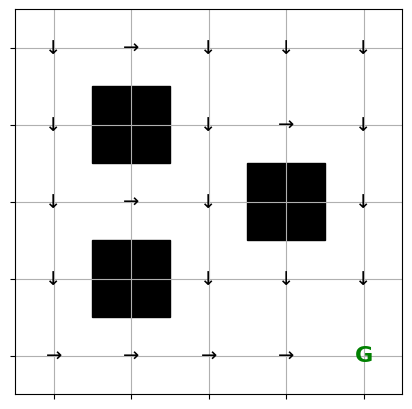


Optimal Policy for gamma=0.9


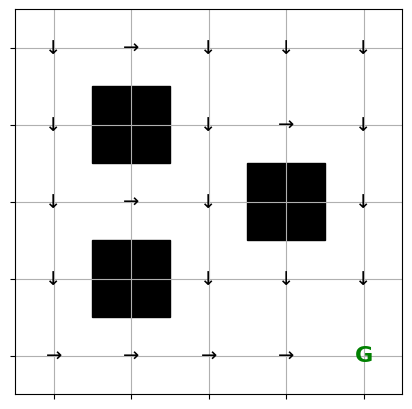


Optimal Policy for gamma=0.99


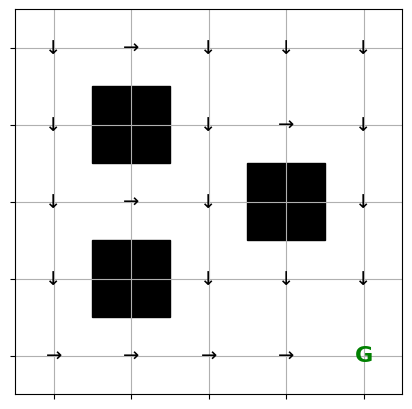

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define Gridworld parameters
grid_size = 5
obstacles = [(1, 1), (2, 3), (3, 1)]  # Cells containing obstacles
goal_state = (4, 4)
actions = ['up', 'down', 'left', 'right']

def get_next_state(state, action):
    """Returns the next state given the current state and action."""
    x, y = state
    if action == 'up':
        next_state = (x - 1, y)
    elif action == 'down':
        next_state = (x + 1, y)
    elif action == 'left':
        next_state = (x, y - 1)
    elif action == 'right':
        next_state = (x, y + 1)

    # Check boundaries and obstacles
    if next_state in obstacles or not (0 <= next_state[0] < grid_size and 0 <= next_state[1] < grid_size):
        return state  # Stay in place if moving into an obstacle or out of bounds
    return next_state

def get_reward(state):
    """Returns the reward for a given state."""
    if state == goal_state:
        return 10
    elif state in obstacles:
        return 0
    else:
        return -1

def policy_evaluation(policy, V, gamma=0.9, theta=1e-4):
    """Evaluates a policy by updating the value function until convergence."""
    while True:
        delta = 0
        for x in range(grid_size):
            for y in range(grid_size):
                state = (x, y)
                if state == goal_state:
                    continue

                old_value = V[state]
                action = policy[state]
                next_state = get_next_state(state, action)
                V[state] = get_reward(state) + gamma * V[next_state]
                delta = max(delta, abs(old_value - V[state]))
        if delta < theta:
            break
    return V

def policy_improvement(V, gamma=0.9):
    """Improves the policy based on the current value function."""
    policy = {}
    for x in range(grid_size):
        for y in range(grid_size):
            state = (x, y)
            if state == goal_state:
                policy[state] = None
                continue

            action_values = {}
            for action in actions:
                next_state = get_next_state(state, action)
                action_values[action] = get_reward(state) + gamma * V[next_state]

            policy[state] = max(action_values, key=action_values.get)
    return policy

def policy_iteration(gamma=0.9):
    """Solves the MDP using policy iteration."""
    policy = {(x, y): np.random.choice(actions) for x in range(grid_size) for y in range(grid_size) if (x, y) != goal_state}
    V = np.zeros((grid_size, grid_size))

    while True:
        V = policy_evaluation(policy, V, gamma)
        new_policy = policy_improvement(V, gamma)
        if new_policy == policy:
            break
        policy = new_policy

    return policy, V

def visualize_policy(policy):
    """Displays the optimal policy as an arrow grid using Matplotlib."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.set_xlim(-0.5, grid_size - 0.5)
    ax.set_ylim(-0.5, grid_size - 0.5)
    ax.set_xticks(range(grid_size))
    ax.set_yticks(range(grid_size))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.grid(True)

    arrow_map = {'up': '↑', 'down': '↓', 'left': '←', 'right': '→'}
    for (x, y), action in policy.items():
        if (x, y) == goal_state:
            ax.text(y, grid_size - x - 1, 'G', ha='center', va='center', fontsize=16, fontweight='bold', color='green')
        elif (x, y) in obstacles:
            ax.add_patch(plt.Rectangle((y - 0.5, grid_size - x - 1 - 0.5), 1, 1, color='black'))
        else:
            ax.text(y, grid_size - x - 1, arrow_map[action], ha='center', va='center', fontsize=14)

    plt.show()

def run_experiment():
    """Runs the policy iteration for different gamma values and visualizes the result."""
    gamma_values = [0.5, 0.9, 0.99]
    for gamma in gamma_values:
        print(f"\nOptimal Policy for gamma={gamma}")
        optimal_policy, _ = policy_iteration(gamma)
        visualize_policy(optimal_policy)

# Run the experiment
run_experiment()


Optimal Policy for gamma=0.5


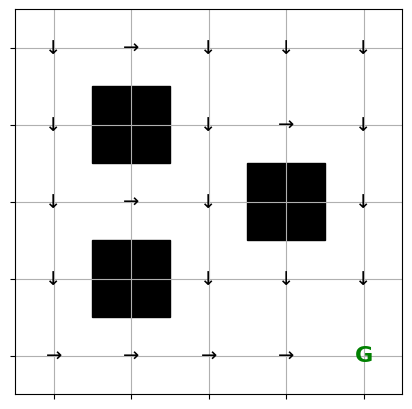

Path taken by the agent: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
Total reward: 3

Optimal Policy for gamma=0.9


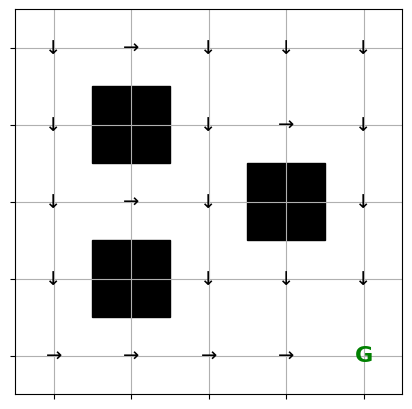

Path taken by the agent: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
Total reward: 3

Optimal Policy for gamma=0.99


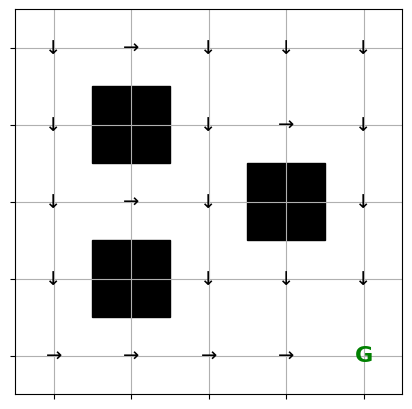

Path taken by the agent: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
Total reward: 3


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define Gridworld parameters
grid_size = 5
obstacles = [(1, 1), (2, 3), (3, 1)]  # Cells containing obstacles
goal_state = (4, 4)
actions = ['up', 'down', 'left', 'right']

def get_next_state(state, action):
    """Returns the next state given the current state and action."""
    x, y = state
    if action == 'up':
        next_state = (x - 1, y)
    elif action == 'down':
        next_state = (x + 1, y)
    elif action == 'left':
        next_state = (x, y - 1)
    elif action == 'right':
        next_state = (x, y + 1)

    # Check boundaries and obstacles
    if next_state in obstacles or not (0 <= next_state[0] < grid_size and 0 <= next_state[1] < grid_size):
        return state  # Stay in place if moving into an obstacle or out of bounds
    return next_state

def get_reward(state):
    """Returns the reward for a given state."""
    if state == goal_state:
        return 10  # High reward for reaching the goal
    elif state in obstacles:
        return -10  # Penalty for hitting an obstacle
    else:
        return -1  # Small penalty for each step

def policy_evaluation(policy, V, gamma=0.9, theta=1e-4):
    """Evaluates a policy by updating the value function until convergence."""
    while True:
        delta = 0
        for x in range(grid_size):
            for y in range(grid_size):
                state = (x, y)
                if state == goal_state:  # Skip the goal state
                    continue

                old_value = V[state]
                action = policy[state]
                next_state = get_next_state(state, action)
                V[state] = get_reward(state) + gamma * V[next_state]
                delta = max(delta, abs(old_value - V[state]))

        if delta < theta:  # Convergence check
            break
    return V

def policy_improvement(V, gamma=0.9):
    """Improves the policy based on the current value function."""
    policy = {}
    for x in range(grid_size):
        for y in range(grid_size):
            state = (x, y)
            if state == goal_state:  # No action for the goal state
                policy[state] = None
                continue

            action_values = {}
            for action in actions:
                next_state = get_next_state(state, action)
                action_values[action] = get_reward(state) + gamma * V[next_state]

            # Choose the action with the highest value
            policy[state] = max(action_values, key=action_values.get)
    return policy

def policy_iteration(gamma=0.9):
    """Solves the MDP using policy iteration."""
    # Initialize random policy and value function
    policy = {(x, y): np.random.choice(actions) for x in range(grid_size) for y in range(grid_size) if (x, y) != goal_state}
    V = {(x, y): 0 for x in range(grid_size) for y in range(grid_size)}  # Initialize value function as a dictionary

    while True:
        V = policy_evaluation(policy, V, gamma)  # Evaluate the current policy
        new_policy = policy_improvement(V, gamma)  # Improve the policy
        if new_policy == policy:  # Check for convergence
            break
        policy = new_policy

    return policy, V

def visualize_policy(policy):
    """Displays the optimal policy as an arrow grid using Matplotlib."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.set_xlim(-0.5, grid_size - 0.5)
    ax.set_ylim(-0.5, grid_size - 0.5)
    ax.set_xticks(range(grid_size))
    ax.set_yticks(range(grid_size))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.grid(True)

    arrow_map = {'up': '↑', 'down': '↓', 'left': '←', 'right': '→'}
    for (x, y), action in policy.items():
        if (x, y) == goal_state:
            ax.text(y, grid_size - x - 1, 'G', ha='center', va='center', fontsize=16, fontweight='bold', color='green')
        elif (x, y) in obstacles:
            ax.add_patch(plt.Rectangle((y - 0.5, grid_size - x - 1 - 0.5), 1, 1, color='black'))
        else:
            ax.text(y, grid_size - x - 1, arrow_map[action], ha='center', va='center', fontsize=14)

    plt.show()

def simulate_path(policy, start_state=(0, 0)):
    """Simulates the agent's path from a start state to the goal state."""
    state = start_state
    path = [state]
    total_reward = 0

    while state != goal_state:
        action = policy[state]
        next_state = get_next_state(state, action)
        reward = get_reward(next_state)
        total_reward += reward
        state = next_state
        path.append(state)

    return path, total_reward

def run_experiment():
    """Runs the policy iteration for different gamma values and visualizes the result."""
    gamma_values = [0.5, 0.9, 0.99]
    for gamma in gamma_values:
        print(f"\nOptimal Policy for gamma={gamma}")
        optimal_policy, _ = policy_iteration(gamma)
        visualize_policy(optimal_policy)

        # Simulate the agent's path and calculate the total reward
        start_state = (0, 0)
        path, total_reward = simulate_path(optimal_policy, start_state)

        print(f"Path taken by the agent: {path}")
        print(f"Total reward: {total_reward}")

# Run the experiment
run_experiment()
